In [1]:
from pathlib import Path

for path in Path("/kaggle/input").rglob("bottle/train/good"):
    root = path.parents[2]
    print("Racine MVTec :", root)
    print("Bottle :", (root / "bottle").exists())
    print("Hazelnut :", (root / "hazelnut").exists())
    print("Transistor :", (root / "transistor").exists())

Racine MVTec : /kaggle/input/datasets/ipythonx/mvtec-ad
Bottle : True
Hazelnut : True
Transistor : True


In [2]:
!git clone --depth 1 \
    --branch feature/us-02-04-data-pipeline \
    https://github.com/MRdrissi/industrial-defect-ai.git \
    /kaggle/working/industrial-defect-ai

Cloning into '/kaggle/working/industrial-defect-ai'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 53 (delta 0), reused 47 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 6.67 MiB | 23.14 MiB/s, done.


In [3]:
import sys
from pathlib import Path

REPO_ROOT = Path("/kaggle/working/industrial-defect-ai")

DATASET_ROOT = Path(
    "/kaggle/input/datasets/ipythonx/mvtec-ad"
)

MANIFEST_DIR = REPO_ROOT / "docs/data/us-02-03"

sys.path.insert(0, str(REPO_ROOT))

from src.data.mvtec_dataset import MVTecDataset
from src.data.transforms import MVTecTransform
from src.data.dataloaders import create_dataloader

print("Pipeline US-02-04 importé avec succès !")
print("Dataset MVTec :", DATASET_ROOT)

Pipeline US-02-04 importé avec succès !
Dataset MVTec : /kaggle/input/datasets/ipythonx/mvtec-ad


In [4]:
categories = ("bottle", "hazelnut", "transistor")
splits = ("train", "val", "test")

transform = MVTecTransform(
    size=(256, 256),
    profile="cae"
)

for category in categories:
    manifest_path = MANIFEST_DIR / f"{category}_manifest.csv"

    print(f"\nCatégorie : {category}")

    for split in splits:
        dataset = MVTecDataset(
            dataset_root=DATASET_ROOT,
            manifest_path=manifest_path,
            category=category,
            split=split,
            transform=transform
        )

        sample = dataset[0]

        print(
            f"  {split:5s} | "
            f"n={len(dataset):3d} | "
            f"image={tuple(sample['image'].shape)} | "
            f"mask={tuple(sample['mask'].shape)} | "
            f"label={sample['label']}"
        )


Catégorie : bottle
  train | n=167 | image=(3, 256, 256) | mask=(1, 256, 256) | label=0
  val   | n= 42 | image=(3, 256, 256) | mask=(1, 256, 256) | label=0
  test  | n= 83 | image=(3, 256, 256) | mask=(1, 256, 256) | label=1

Catégorie : hazelnut
  train | n=313 | image=(3, 256, 256) | mask=(1, 256, 256) | label=0
  val   | n= 78 | image=(3, 256, 256) | mask=(1, 256, 256) | label=0
  test  | n=110 | image=(3, 256, 256) | mask=(1, 256, 256) | label=1

Catégorie : transistor
  train | n=170 | image=(3, 256, 256) | mask=(1, 256, 256) | label=0
  val   | n= 43 | image=(3, 256, 256) | mask=(1, 256, 256) | label=0
  test  | n=100 | image=(3, 256, 256) | mask=(1, 256, 256) | label=1


In [5]:

import json
import subprocess

import numpy as np
import torch
from PIL import Image

CATEGORIES = ("bottle", "hazelnut", "transistor")
SPLITS = ("train", "val", "test")

EXPECTED_COUNTS = {
    "bottle": {"train": 167, "val": 42, "test": 83},
    "hazelnut": {"train": 313, "val": 78, "test": 110},
    "transistor": {"train": 170, "val": 43, "test": 100},
}

transform = MVTecTransform(
    size=(256, 256),
    profile="cae",
)

report = {
    "task": "ST-02-04-02",
    "image_size": [256, 256],
    "profile": "cae",
    "categories": {},
}

total_images = 0
total_anomalies = 0

for category in CATEGORIES:
    stats = {
        "splits": {},
        "images_checked": 0,
        "anomalies_checked": 0,
        "vanished_masks": [],
    }

    for split in SPLITS:
        dataset = MVTecDataset(
            dataset_root=DATASET_ROOT,
            manifest_path=MANIFEST_DIR / f"{category}_manifest.csv",
            category=category,
            split=split,
            transform=transform,
        )

        assert len(dataset) == EXPECTED_COUNTS[category][split]

        stats["splits"][split] = len(dataset)

        for index in range(len(dataset)):
            sample = dataset[index]
            metadata = dataset.samples[index]

            # 1. Vérifier le contrat des tenseurs.
            assert sample["image"].shape == (3, 256, 256)
            assert sample["mask"].shape == (1, 256, 256)

            assert sample["image"].dtype == torch.float32
            assert sample["mask"].dtype == torch.bool

            assert torch.isfinite(sample["image"]).all()
            assert sample["image"].min().item() >= 0.0
            assert sample["image"].max().item() <= 1.0

            # 2. Vérifier l'identité et le label.
            assert sample["label"] == metadata["label"]
            assert sample["category"] == category
            assert sample["image_path"] == metadata["image_path"]

            if sample["label"] == 0:
                # Toute image normale possède un masque nul.
                assert not sample["mask"].any().item()

            else:
                total_anomalies += 1
                stats["anomalies_checked"] += 1

                # 3. Comparer le masque retourné avec
                #    le masque source redimensionné.
                mask_path = DATASET_ROOT / metadata["mask_path"]

                with Image.open(mask_path) as source:
                    source_mask = source.convert("L")

                source_pixels = np.asarray(source_mask) > 127

                resized_mask = source_mask.resize(
                    (256, 256),
                    resample=Image.Resampling.NEAREST,
                )

                expected_mask = torch.from_numpy(
                    np.array(resized_mask) > 127
                )

                assert torch.equal(
                    sample["mask"][0].cpu(),
                    expected_mask,
                ), f"Masque mal transformé : {mask_path}"

                # Détecter les défauts entièrement disparus.
                if (
                    source_pixels.any()
                    and not expected_mask.any().item()
                ):
                    stats["vanished_masks"].append(
                        metadata["image_path"]
                    )

            total_images += 1
            stats["images_checked"] += 1

    report["categories"][category] = stats

    print(
        f"{category:10s} | "
        f"images={stats['images_checked']:3d} | "
        f"anomalies={stats['anomalies_checked']:3d} | "
        f"masques disparus={len(stats['vanished_masks'])}"
    )

assert total_images == 1106
assert total_anomalies == 173

report["total_images"] = total_images
report["total_anomalies"] = total_anomalies
report["git_commit"] = subprocess.check_output(
    ["git", "-C", str(REPO_ROOT), "rev-parse", "HEAD"],
    text=True,
).strip()

report_path = Path(
    "/kaggle/working/us-02-04-validation-report.json"
)

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8",
)

print("\nValidation exhaustive terminée.")
print("Images :", total_images)
print("Anomalies :", total_anomalies)
print("Rapport :", report_path)


bottle     | images=292 | anomalies= 63 | masques disparus=0
hazelnut   | images=501 | anomalies= 70 | masques disparus=0
transistor | images=313 | anomalies= 40 | masques disparus=0

Validation exhaustive terminée.
Images : 1106
Anomalies : 173
Rapport : /kaggle/working/us-02-04-validation-report.json


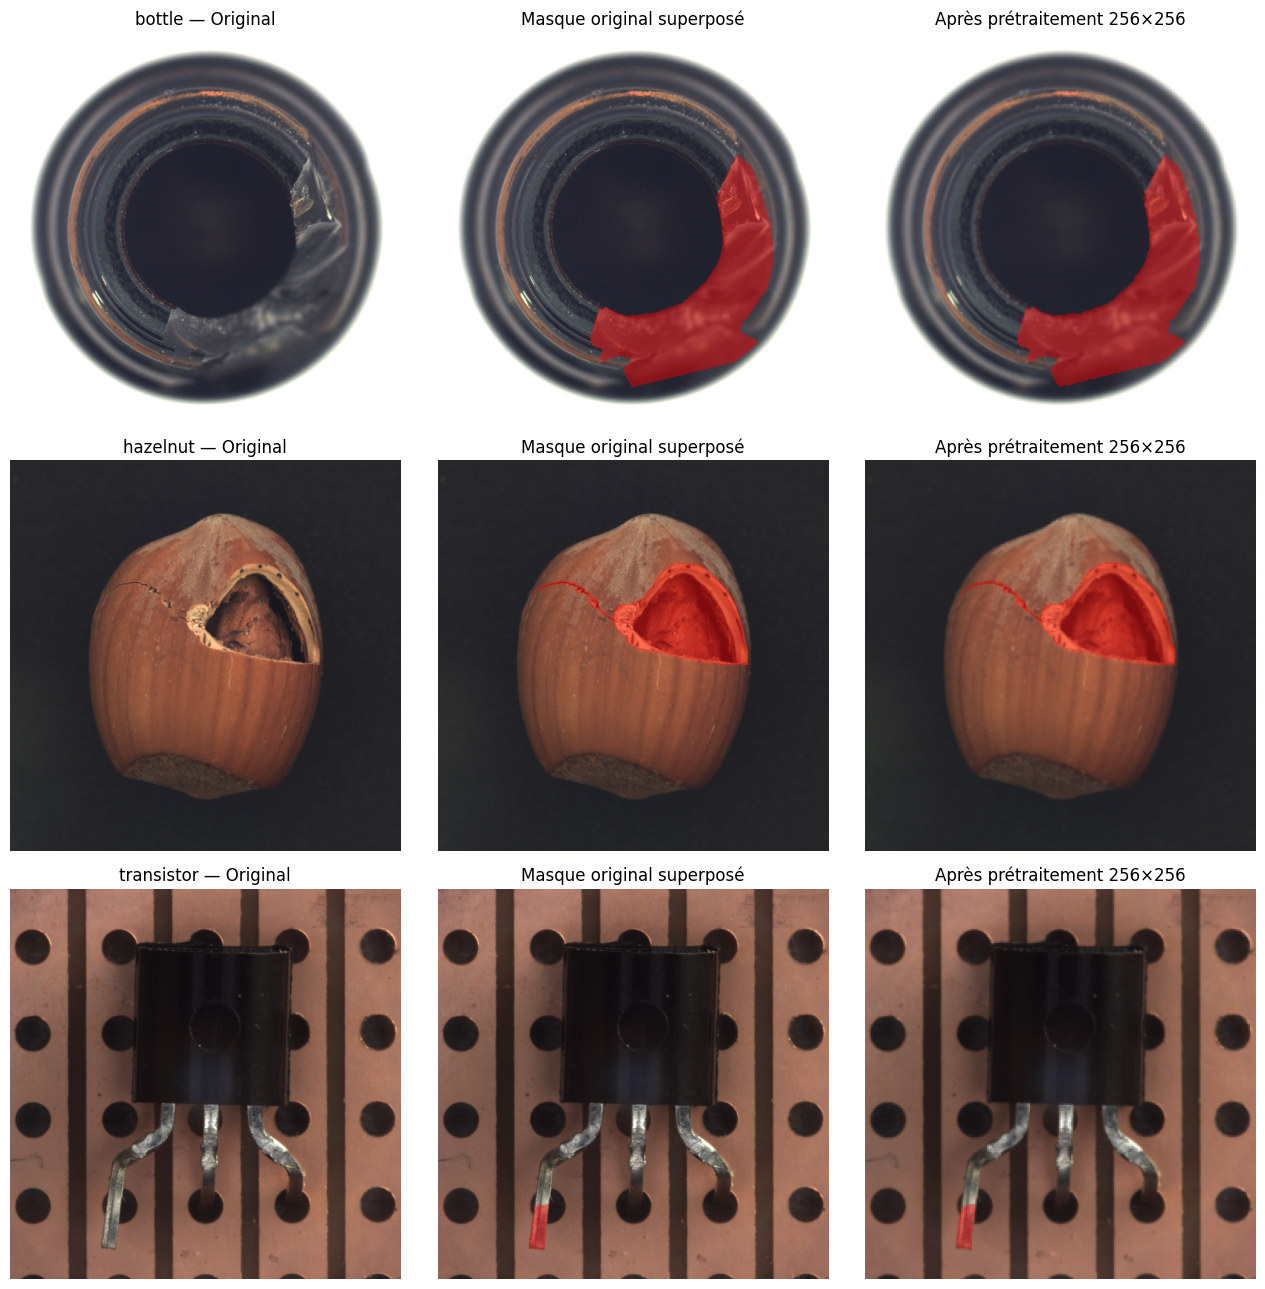

In [6]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


def overlay_mask(image, mask, alpha=0.45):
    """Superpose en rouge les pixels anormaux."""
    result = image.astype(np.float32).copy()
    result[mask] = (
        (1 - alpha) * result[mask]
        + alpha * np.array([255, 0, 0])
    )
    return result.clip(0, 255).astype(np.uint8)


fig, axes = plt.subplots(3, 3, figsize=(13, 13))

for row, category in enumerate(CATEGORIES):
    dataset = MVTecDataset(
        dataset_root=DATASET_ROOT,
        manifest_path=MANIFEST_DIR / f"{category}_manifest.csv",
        category=category,
        split="test",
        transform=MVTecTransform(
            size=(256, 256),
            profile="cae",
        ),
    )

    # Sélectionner une anomalie réelle.
    index = next(
        i for i, meta in enumerate(dataset.samples)
        if meta["label"] == 1
    )

    sample = dataset[index]
    metadata = dataset.samples[index]

    with Image.open(
        DATASET_ROOT / metadata["image_path"]
    ) as source:
        original_image = np.array(source.convert("RGB"))

    with Image.open(
        DATASET_ROOT / metadata["mask_path"]
    ) as source:
        original_mask = np.array(source.convert("L")) > 127

    processed_image = (
        sample["image"]
        .permute(1, 2, 0)
        .cpu()
        .numpy() * 255
    ).clip(0, 255).astype(np.uint8)

    processed_mask = sample["mask"][0].cpu().numpy()

    axes[row, 0].imshow(original_image)
    axes[row, 0].set_title(f"{category} — Original")

    axes[row, 1].imshow(
        overlay_mask(original_image, original_mask)
    )
    axes[row, 1].set_title("Masque original superposé")

    axes[row, 2].imshow(
        overlay_mask(processed_image, processed_mask)
    )
    axes[row, 2].set_title("Après prétraitement 256×256")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:

import torch

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

for category in ("bottle", "hazelnut", "transistor"):
    manifest = MANIFEST_DIR / f"{category}_manifest.csv"

    common = {
        "dataset_root": DATASET_ROOT,
        "manifest_path": manifest,
        "category": category,
        "split": "test",
    }

    cae = MVTecDataset(
        **common,
        transform=MVTecTransform(
            size=(256, 256),
            profile="cae",
        ),
    )

    patchcore = MVTecDataset(
        **common,
        transform=MVTecTransform(
            size=(256, 256),
            profile="patchcore",
        ),
    )

    # Sélectionner une anomalie réelle.
    idx = next(
        i for i, row in enumerate(cae.samples)
        if row["label"] == 1
    )

    sample_cae = cae[idx]
    sample_patch = patchcore[idx]

    expected = (sample_cae["image"] - mean) / std

    torch.testing.assert_close(
        sample_patch["image"],
        expected,
        rtol=1e-5,
        atol=1e-5,
    )

    assert torch.equal(
        sample_cae["mask"],
        sample_patch["mask"],
    )

    assert sample_cae["label"] == sample_patch["label"]
    assert sample_cae["image_path"] == sample_patch["image_path"]

    print(f"{category}: normalisation et masque OK")

print("\nValidation PatchCore réussie.")


bottle: normalisation et masque OK
hazelnut: normalisation et masque OK
transistor: normalisation et masque OK

Validation PatchCore réussie.
